# Corrected Retraining — File-Level Split (No Leakage)
This notebook retrains the model from scratch using a proper file-level train/test split, then overwrites the saved model/scaler/encoder in `apps/models/` with the corrected versions.

## 1. Setup — find project root, imports

In [1]:
import sys, os

current = os.getcwd()
while not os.path.exists(os.path.join(current, 'apps')) and current != os.path.dirname(current):
    current = os.path.dirname(current)
sys.path.append(current)
print('Project root:', current)

Project root: c:\Users\hp\predictive-maintenance-diagnosis


In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from apps.models.model_def import FaultDiagnosisNet

## 2. Load data — MUST include `file_id` column

In [3]:
data_path = os.path.join(current, 'apps', 'data', 'processed', 'mafaulda_features_final.csv')
df = pd.read_csv(data_path)

print(df.shape)
assert 'file_id' in df.columns, 'file_id column missing — re-run extraction with file_id added before continuing!'
print('file_id present — safe to proceed')
print(df['fault_type'].value_counts())

(244000, 74)
file_id present — safe to proceed
fault_type
underhang_bearing          68076
overhang_bearing           62586
imbalance                  40626
vertical_misalignment      36722
horizontal_misalignment    24034
normal                     11956
Name: count, dtype: int64


## 3. Feature columns

In [4]:
feature_cols = [c for c in df.columns if c not in ['fault_type', 'file_id']]
print(len(feature_cols), 'features')

72 features


## 4. THE CRITICAL FIX — file-level split (GroupShuffleSplit)

In [5]:
gss = GroupShuffleSplit(test_size=0.2, n_splits=1, random_state=42)
train_idx, test_idx = next(gss.split(df, groups=df['file_id']))

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

X_train = train_df[feature_cols]
X_test = test_df[feature_cols]
y_train = train_df['fault_type']
y_test = test_df['fault_type']

print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (195200, 72) Test: (48800, 72)


In [6]:
# MANDATORY CHECK — confirm zero file overlap between train and test
overlap = set(train_df['file_id']) & set(test_df['file_id'])
print('Files appearing in BOTH train and test:', len(overlap))
assert len(overlap) == 0, 'LEAKAGE STILL PRESENT — do not proceed until this is 0!'
print('Confirmed: no file-level leakage. Safe to train.')

Files appearing in BOTH train and test: 0
Confirmed: no file-level leakage. Safe to train.


## 5. Scaling — fit on train only

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 6. Labels and class weights

In [8]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

classes = np.unique(y_train_encoded)
class_weights = compute_class_weight('balanced', classes=classes, y=y_train_encoded)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print(dict(zip(le.classes_, class_weights)))

{'horizontal_misalignment': 1.6563146997929608, 'imbalance': 1.0296010296010296, 'normal': 3.755868544600939, 'overhang_bearing': 0.624512099921936, 'underhang_bearing': 0.6006006006006006, 'vertical_misalignment': 1.1204481792717087}


## 7. Dataset / DataLoader

In [9]:
class FaultDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = FaultDataset(X_train_scaled, y_train_encoded)
test_dataset = FaultDataset(X_test_scaled, y_test_encoded)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

## 8. FRESH model — do not reuse any old trained model object

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

input_size = X_train_scaled.shape[1]
num_classes = len(le.classes_)

model = FaultDiagnosisNet(input_size=input_size, num_classes=num_classes)  # freshly initialized
model = model.to(device)
weights_tensor = weights_tensor.to(device)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

Using device: cpu


## 9. Training loop

In [11]:
n_epochs = 30
train_losses, val_losses = [], []

for epoch in range(n_epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * X_batch.size(0)
    train_loss = running_loss / len(train_dataset)
    train_losses.append(train_loss)

    model.eval()
    val_running_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_running_loss += loss.item() * X_batch.size(0)
    val_loss = val_running_loss / len(test_dataset)
    val_losses.append(val_loss)

    print(f"Epoch {epoch+1}/{n_epochs} - train_loss: {train_loss:.4f} - val_loss: {val_loss:.4f}")

Epoch 1/30 - train_loss: 0.7840 - val_loss: 0.2676
Epoch 2/30 - train_loss: 0.3886 - val_loss: 0.1891
Epoch 3/30 - train_loss: 0.2888 - val_loss: 0.1176
Epoch 4/30 - train_loss: 0.2420 - val_loss: 0.1047
Epoch 5/30 - train_loss: 0.2179 - val_loss: 0.1818
Epoch 6/30 - train_loss: 0.1998 - val_loss: 0.0927
Epoch 7/30 - train_loss: 0.1899 - val_loss: 0.1036
Epoch 8/30 - train_loss: 0.1815 - val_loss: 0.1152
Epoch 9/30 - train_loss: 0.1749 - val_loss: 0.1004
Epoch 10/30 - train_loss: 0.1677 - val_loss: 0.1427
Epoch 11/30 - train_loss: 0.1645 - val_loss: 0.3317
Epoch 12/30 - train_loss: 0.1583 - val_loss: 0.1261
Epoch 13/30 - train_loss: 0.1571 - val_loss: 0.4253
Epoch 14/30 - train_loss: 0.1541 - val_loss: 0.3407
Epoch 15/30 - train_loss: 0.1498 - val_loss: 0.3261
Epoch 16/30 - train_loss: 0.1466 - val_loss: 0.9580
Epoch 17/30 - train_loss: 0.1483 - val_loss: 1.4402
Epoch 18/30 - train_loss: 0.1433 - val_loss: 1.2324
Epoch 19/30 - train_loss: 0.1422 - val_loss: 0.7413
Epoch 20/30 - train_l

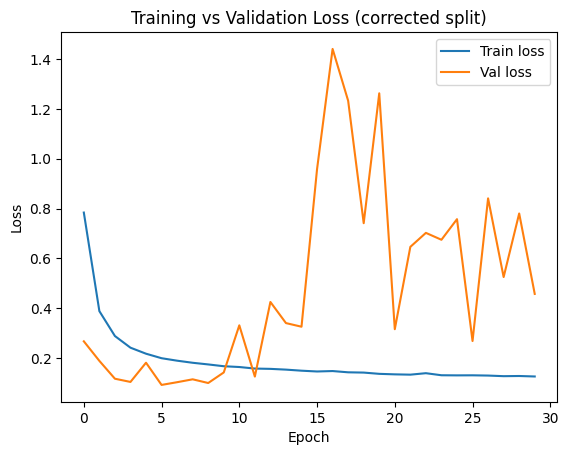

In [12]:
plt.plot(train_losses, label='Train loss')
plt.plot(val_losses, label='Val loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.title('Training vs Validation Loss (corrected split)')
plt.show()

## 10. Evaluation — the real, trustworthy numbers

                         precision    recall  f1-score   support

horizontal_misalignment       0.87      0.98      0.92      4392
              imbalance       0.99      0.99      0.99      9028
                 normal       0.98      0.93      0.95      3294
       overhang_bearing       1.00      1.00      1.00     10492
      underhang_bearing       1.00      0.99      1.00     13908
  vertical_misalignment       0.99      0.94      0.96      7686

               accuracy                           0.98     48800
              macro avg       0.97      0.97      0.97     48800
           weighted avg       0.98      0.98      0.98     48800



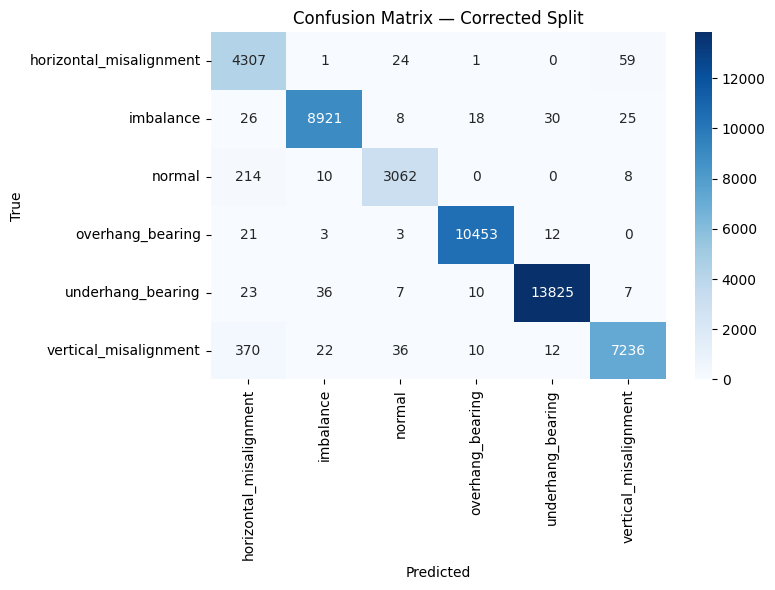

In [13]:
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        outputs = model(X_batch)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_batch.numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — Corrected Split')
plt.tight_layout()
plt.show()

## 11. Save — overwrite the model/scaler/encoder used by the app

In [14]:
model_dir = os.path.join(current, 'apps', 'models')

torch.save(model.state_dict(), os.path.join(model_dir, 'fault_diagnosis_model.pth'))
joblib.dump(scaler, os.path.join(model_dir, 'scaler.pkl'))
joblib.dump(le, os.path.join(model_dir, 'label_encoder.pkl'))

print('Saved corrected model, scaler, and label encoder to', model_dir)

Saved corrected model, scaler, and label encoder to c:\Users\hp\predictive-maintenance-diagnosis\apps\models


In [15]:
# CONFIRM the save actually happened with a fresh timestamp
import time

pth_path = os.path.join(model_dir, 'fault_diagnosis_model.pth')
mtime = os.path.getmtime(pth_path)
print('Model file last modified:', time.ctime(mtime))


Model file last modified: Fri Aug 14 18:46:46 2026


In [16]:
import pandas as pd

SAMPLE_FILE = "C:/Users/hp/predictive-maintenance-diagnosis/apps/data/raw/MAFAULDA/normal/18.432.csv"
data = pd.read_csv(SAMPLE_FILE, header=None).values

print(f"File length: {len(data)}")
print(f"Window size: 2048")
print(f"Clean windows: {len(data) // 2048}, remainder: {len(data) % 2048}")

File length: 250000
Window size: 2048
Clean windows: 122, remainder: 144


In [17]:
import json

sample = X_test.iloc[0].to_dict()
payload = {
    "machine_id": "machine1",
    "features": sample
}

print(json.dumps(payload, indent=2))

{
  "machine_id": "machine1",
  "features": {
    "tachometer_max": 4.8255,
    "tachometer_min": -1.0343,
    "tachometer_mean": 0.2857071972656249,
    "tachometer_sd": 1.9237314185922276,
    "tachometer_rms": 1.9448319139319576,
    "tachometer_skewness": 1.7461671368917082,
    "tachometer_kurtosis": 1.0695474994287792,
    "tachometer_crest": 2.481191287242948,
    "tachometer_form": 1.5493056379311128,
    "underhang_axial_max": 1.4481,
    "underhang_axial_min": -2.9366,
    "underhang_axial_mean": -0.1473666333007812,
    "underhang_axial_sd": 1.0598727887047188,
    "underhang_axial_rms": 1.070068807529275,
    "underhang_axial_skewness": -0.2311294798857259,
    "underhang_axial_kurtosis": -1.111262226535304,
    "underhang_axial_crest": 2.744309505461087,
    "underhang_axial_form": 1.1525358463515478,
    "underhang_radial_max": 0.4864,
    "underhang_radial_min": -1.0767,
    "underhang_radial_mean": -0.0147842817529296,
    "underhang_radial_sd": 0.3221825460050024,
    

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import time

# --- Baseline 1: Random Forest ---
start = time.time()
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train_scaled, y_train_encoded)
rf_train_time = time.time() - start

rf_preds = rf_model.predict(X_test_scaled)
rf_accuracy = accuracy_score(y_test_encoded, rf_preds)

print("=== Random Forest Baseline ===")
print(f"Training time: {rf_train_time:.2f}s")
print(classification_report(y_test_encoded, rf_preds, target_names=le.classes_))

=== Random Forest Baseline ===
Training time: 268.83s
                         precision    recall  f1-score   support

horizontal_misalignment       0.97      0.98      0.98      4392
              imbalance       0.99      0.99      0.99      9028
                 normal       1.00      0.98      0.99      3294
       overhang_bearing       1.00      1.00      1.00     10492
      underhang_bearing       1.00      1.00      1.00     13908
  vertical_misalignment       0.99      0.98      0.98      7686

               accuracy                           0.99     48800
              macro avg       0.99      0.99      0.99     48800
           weighted avg       0.99      0.99      0.99     48800



In [19]:
pip install xgboost --break-system-packages

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 1.8/48.9 MB 12.6 MB/s eta 0:00:04
   -- ------------------------------------- 3.1/48.9 MB 8.0 MB/s eta 0:00:06
   --- ------------------------------------ 4.2/48.9 MB 7.6 MB/s eta 0:00:06
   ---- ----------------------------------- 5.0/48.9 MB 5.9 MB/s eta 0:00:08
   ---- ----------------------------------- 5.2/48.9 MB 5.2 MB/s eta 0:00:09
   ---- ----------------------------------- 5.2/48.9 MB 5.2 MB/s eta 0:00:09
   ---- ----------------------------------- 5.5/48.9 MB 4.1 MB/s eta 0:00:11
   ---- ----------------------------------- 5.8/48.9 MB 3.6 MB/s eta 0:00:12
   ----- ---------------------------------- 6.3/48.9 MB 3.3 MB/s eta 0:00:13
   ----- ---------------------------------- 6.8/48.9 MB 3.2 MB/s eta 0:00:14
   ----- ---------------------------------- 7.3/48.9 MB 3.1 MB/s eta 0:00:14
   ------ --------------------------------- 7.9/48.9 MB 3.1 MB/s eta 0:00:14
   --


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import xgboost as xgb

# --- Baseline 2: XGBoost ---
start = time.time()
xgb_model = xgb.XGBClassifier(n_estimators=200, random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train_scaled, y_train_encoded)
xgb_train_time = time.time() - start

xgb_preds = xgb_model.predict(X_test_scaled)
xgb_accuracy = accuracy_score(y_test_encoded, xgb_preds)

print("=== XGBoost Baseline ===")
print(f"Training time: {xgb_train_time:.2f}s")
print(classification_report(y_test_encoded, xgb_preds, target_names=le.classes_))

=== XGBoost Baseline ===
Training time: 73.10s
                         precision    recall  f1-score   support

horizontal_misalignment       0.98      0.99      0.98      4392
              imbalance       0.98      0.99      0.99      9028
                 normal       1.00      0.95      0.97      3294
       overhang_bearing       1.00      1.00      1.00     10492
      underhang_bearing       1.00      1.00      1.00     13908
  vertical_misalignment       0.99      0.99      0.99      7686

               accuracy                           0.99     48800
              macro avg       0.99      0.99      0.99     48800
           weighted avg       0.99      0.99      0.99     48800



In [21]:

# Get your FaultDiagnosisNet's existing metrics (from your saved evaluation)
nn_accuracy = accuracy_score(all_labels, all_preds)  # from your corrected retrain notebook

comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'FaultDiagnosisNet (custom)'],
    'Accuracy': [rf_accuracy, xgb_accuracy, nn_accuracy],
    'Training Time (s)': [rf_train_time, xgb_train_time, 'see training loop'],
})
print(comparison)

                        Model  Accuracy  Training Time (s)
0               Random Forest  0.992439         268.830614
1                     XGBoost  0.992029          73.098861
2  FaultDiagnosisNet (custom)  0.979590  see training loop


In [22]:
from sklearn.metrics import classification_report

print("=== Random Forest — per class ===")
print(classification_report(y_test_encoded, rf_preds, target_names=le.classes_))

print("=== FaultDiagnosisNet — per class ===")
print(classification_report(all_labels, all_preds, target_names=le.classes_))

=== Random Forest — per class ===
                         precision    recall  f1-score   support

horizontal_misalignment       0.97      0.98      0.98      4392
              imbalance       0.99      0.99      0.99      9028
                 normal       1.00      0.98      0.99      3294
       overhang_bearing       1.00      1.00      1.00     10492
      underhang_bearing       1.00      1.00      1.00     13908
  vertical_misalignment       0.99      0.98      0.98      7686

               accuracy                           0.99     48800
              macro avg       0.99      0.99      0.99     48800
           weighted avg       0.99      0.99      0.99     48800

=== FaultDiagnosisNet — per class ===
                         precision    recall  f1-score   support

horizontal_misalignment       0.87      0.98      0.92      4392
              imbalance       0.99      0.99      0.99      9028
                 normal       0.98      0.93      0.95      3294
       overhan